In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [43]:
df=pd.read_csv("transactions_TP2.csv")
print(df.shape)
print(df.head())
print(df.dtypes)

(3045, 12)
  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat           non    aucune_fraude   

   fraude  
0       0  
1       0  
2       0  
3  

In [44]:
print(df.isna().sum())

id_operation          0
id_client             0
montant_dh          110
anciennete_mois     137
nb_ops_24h           53
heure                 0
canal               159
appareil            122
region              103
international         0
resultat_enquete      0
fraude                0
dtype: int64


In [45]:
print(df.isna().mean()*100)

id_operation        0.000000
id_client           0.000000
montant_dh          3.612479
anciennete_mois     4.499179
nb_ops_24h          1.740558
heure               0.000000
canal               5.221675
appareil            4.006568
region              3.382594
international       0.000000
resultat_enquete    0.000000
fraude              0.000000
dtype: float64


In [46]:
manq=pd.DataFrame({
    "nombre":df.isna().sum(),
    "pourcentage":(df.isna().mean()*100).round(2)
})
manq=manq.sort_values("pourcentage",ascending=False)
print(manq)

                  nombre  pourcentage
canal                159         5.22
anciennete_mois      137         4.50
appareil             122         4.01
montant_dh           110         3.61
region               103         3.38
nb_ops_24h            53         1.74
id_operation           0         0.00
id_client              0         0.00
heure                  0         0.00
international          0         0.00
resultat_enquete       0         0.00
fraude                 0         0.00


In [47]:
nb_doublons=df.duplicated(subset="id_operation").sum()
print("nombre de doublons:",nb_doublons)

nombre de doublons: 45


In [48]:
df=df.drop_duplicates(subset="id_operation")
print("lignes restantes:",df.shape[0])

lignes restantes: 3000


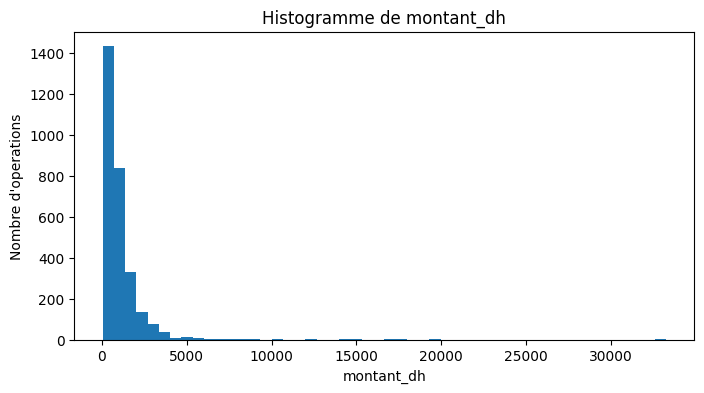

In [49]:
plt.figure(figsize=(8,4))
plt.hist(df["montant_dh"].dropna(),bins=50)
plt.title("Histogramme de montant_dh")
plt.xlabel("montant_dh")
plt.ylabel("Nombre d'operations")
plt.show()

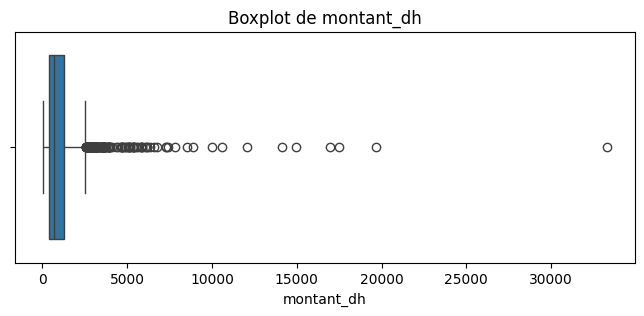

In [50]:
plt.figure(figsize=(8,3))
sns.boxplot(x=df["montant_dh"])
plt.title("Boxplot de montant_dh")
plt.show()

In [51]:
print(df["montant_dh"].describe())
print(df["montant_dh"].nlargest(5))

count     2893.000000
mean      1028.359457
std       1320.830647
min         36.410000
25%        389.530000
50%        708.660000
75%       1249.480000
max      33281.230000
Name: montant_dh, dtype: float64
2660    33281.23
539     19658.42
1775    17496.64
1557    16962.99
2556    14951.95
Name: montant_dh, dtype: float64


fraude
0    2742
1     258
Name: count, dtype: int64
fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


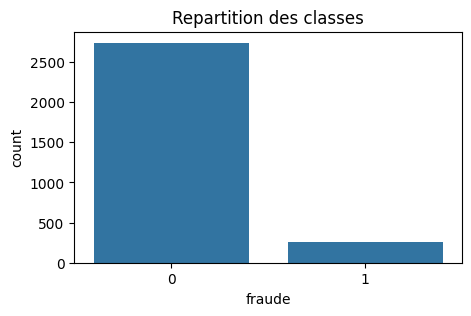

In [52]:
print(df["fraude"].value_counts())
print(df["fraude"].value_counts(normalize=True)*100)
plt.figure(figsize=(5,3))
sns.countplot(x="fraude",data=df)
plt.title("Repartition des classes")
plt.show()

In [53]:
print(pd.crosstab(df["resultat_enquete"],df["fraude"]))

fraude               0    1
resultat_enquete           
aucune_fraude     2742    0
fraude_confirmee     0  258


In [54]:
X=df.drop(columns=["id_operation","id_client","resultat_enquete","fraude"])
y=df["fraude"]
print(X.shape)
print(X.columns.tolist())

(3000, 8)
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international']


In [55]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(X,y, test_size=0.20, stratify=y, random_state=42)

print("Reference:",X_train.shape)
print("Verification:",X_test.shape)

print(y_train.value_counts(normalize=True)*100)
print(y_test.value_counts(normalize=True)*100)


Reference: (2400, 8)
Verification: (600, 8)
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64
fraude
0    91.333333
1     8.666667
Name: proportion, dtype: float64


In [56]:
num_cols= X_train.select_dtypes(include="number").columns.tolist()
cat_cols=X_train.select_dtypes(exclude="number").columns.tolist()
print("Numerique:", num_cols)
print("Categorielles:", cat_cols)


Numerique: ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Categorielles: ['canal', 'appareil', 'region', 'international']


In [57]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
X_train_num = num_pipe.fit_transform(X_train[num_cols])
X_test_num=num_pipe.transform(X_test[num_cols])

In [58]:
print("Medianes :", num_pipe.named_steps["imputer"].statistics_)
print("Moyennes:", num_pipe.named_steps["scaler"].mean_)
print("Ecarts-types:", num_pipe.named_steps["scaler"].scale_)

Medianes : [710.79  87.     3.    11.  ]
Moyennes: [1020.672925     87.48333333    2.72083333   11.47      ]
Ecarts-types: [1327.6254132    49.48592112    1.64607593    6.99546996]


In [59]:
print(np.isnan(X_train_num).sum(), np.isnan(X_test_num).sum())

0 0


In [60]:
from sklearn.preprocessing import OneHotEncoder

cat_pipe= Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("OneHot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

In [61]:
from sklearn.compose import ColumnTransformer

prep = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

X_train_prep = prep.fit_transform(X_train)
X_test_prep = prep.transform(X_test)

print("Référence avant :", X_train.shape, "→ après :", X_train_prep.shape)
print("Vérification avant :", X_test.shape, "→ après :", X_test_prep.shape)

Référence avant : (2400, 8) → après : (2400, 18)
Vérification avant : (600, 8) → après : (600, 18)


In [62]:
print(prep.get_feature_names_out())
print(np.isnan(X_train_prep).sum(), np.isnan(X_test_prep).sum())

['num__montant_dh' 'num__anciennete_mois' 'num__nb_ops_24h' 'num__heure'
 'cat__canal_agence' 'cat__canal_application' 'cat__canal_site_web'
 'cat__canal_telephone' 'cat__appareil_mobile' 'cat__appareil_ordinateur'
 'cat__appareil_terminal' 'cat__region_Autre'
 'cat__region_Casablanca-Settat' 'cat__region_Draa-Tafilalet'
 'cat__region_Marrakech-Safi' 'cat__region_Souss-Massa'
 'cat__international_non' 'cat__international_oui']
0 0


In [63]:
from sklearn.preprocessing import RobustScaler

num_pipe_rob = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])
num_pipe_rob.fit(X_train[num_cols])

exemples = pd.DataFrame({
    "montant_dh": [700, 30000],
    "anciennete_mois": [87, 87],
    "nb_ops_24h": [3, 3],
    "heure": [11, 11]
})[num_cols]

print("StandardScaler :", num_pipe.transform(exemples)[:, 0])
print("RobustScaler   :", num_pipe_rob.transform(exemples)[:, 0])

StandardScaler : [-0.24153871 21.82793941]
RobustScaler   : [-1.32157511e-02  3.58738563e+01]


In [64]:
Q1= X_train["montant_dh"].quantile(0.25)
Q3=X_train["montant_dh"].quantile(0.75)
IQR=Q3-Q1
print("Q1=", Q1, "|Q3=", Q3, "|IQR=", IQR)

Q1= 393.095 |Q3= 1249.8775 |IQR= 856.7825


In [65]:
L= Q1-1.5 * IQR
U= Q3+1.5 * IQR
out= X_train[(X_train["montant_dh"]<L)|(X_train["montant_dh"]>U)]

print("limites :",L,U)
print("Lignes concernees :", len(out))
print(out["montant_dh"].sort_values(ascending=False).head(10))

limites : -892.0787499999999 2535.05125
Lignes concernees : 146
2660    33281.23
539     19658.42
1775    17496.64
2556    14951.95
65      14135.85
32      10598.93
1313    10028.37
2145     8910.60
1914     7823.15
1096     7400.94
Name: montant_dh, dtype: float64


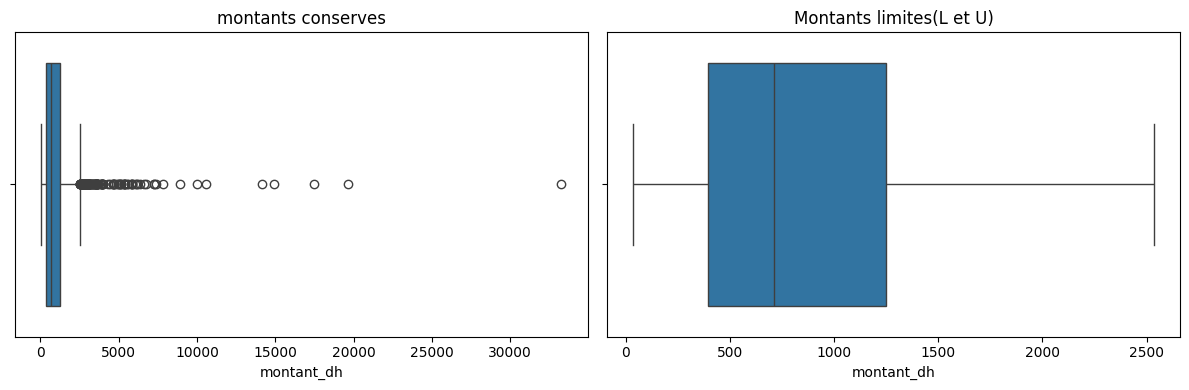

In [66]:
montant_clip = X_train["montant_dh"].clip(lower=L, upper=U)

fig, axes = plt.subplots(1,2, figsize=(12,4))
sns.boxplot(x=X_train["montant_dh"], ax=axes[0])
axes[0].set_title("montants conserves")
sns.boxplot(x=montant_clip, ax=axes[1])
axes[1].set_title("Montants limites(L et U)")
plt.tight_layout()
plt.show()

In [67]:
from sklearn.preprocessing import MinMaxScaler , StandardScaler, RobustScaler

col=["montant_dh"]
mm= MinMaxScaler().fit(X_train[col])
sd= StandardScaler().fit(X_train[col])
rb= RobustScaler().fit(X_train[col])

mm_ref= mm.transform(X_train[col])[:, 0]
sd_ref= sd.transform(X_train[col])[:, 0]
rb_ref= rb.transform(X_train[col])[:, 0]

mm_ver= mm.transform(X_test[col])[:, 0]
sd_ver= sd.transform(X_test[col])[:, 0]
rb_ver= rb.transform(X_test[col])[:, 0]

In [68]:
exemples= pd.DataFrame({"montant_dh":[300.0, 700.0, 1200.0, 30000.0]})

tableau= pd.DataFrame({
    "Montant(DH)": exemples["montant_dh"],
    "Min-Max": mm.transform(exemples)[:, 0],
    "Z-score": sd.transform(exemples)[:, 0],
    "Robust": rb.transform(exemples)[:, 0]
}).round(3)
print(tableau)

   Montant(DH)  Min-Max  Z-score  Robust
0        300.0    0.008   -0.542  -0.479
1        700.0    0.020   -0.246  -0.013
2       1200.0    0.035    0.124   0.571
3      30000.0    0.901   21.438  34.185


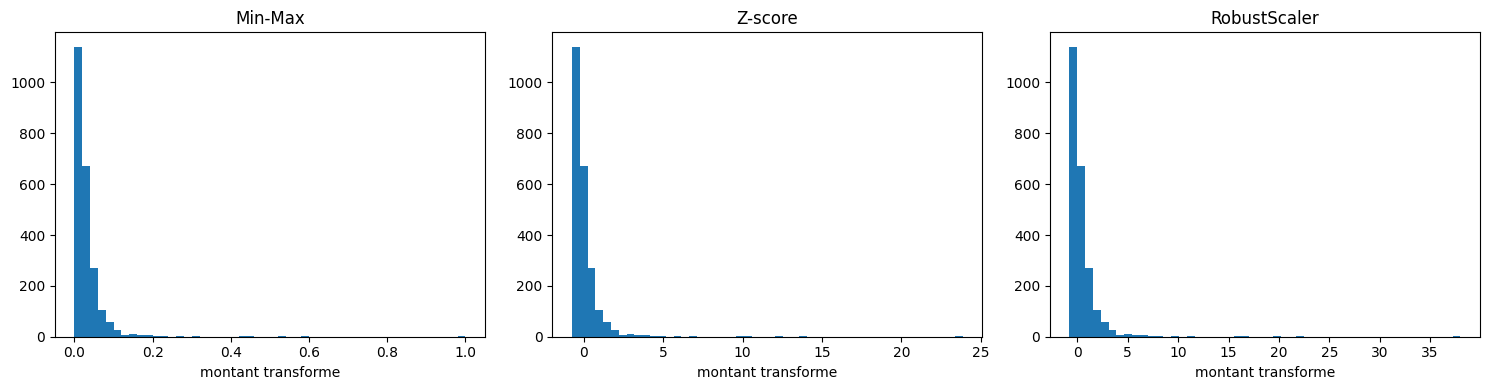

In [69]:
fig, axes= plt.subplots(1, 3, figsize=(15, 4))
donnees= [("Min-Max", mm_ref), ("Z-score", sd_ref), ("RobustScaler", rb_ref)]

for ax, (nom, vals) in zip(axes, donnees):
    ax.hist(pd.Series(vals).dropna(), bins=50)
    ax.set_title(nom)
    ax.set_xlabel("montant transforme")
plt.tight_layout()
plt.show()

In [70]:
ex_train= pd.DataFrame({"x":[100.0, 200.0, 300.0]})
s= MinMaxScaler().fit(ex_train)
print(s.transform(pd.DataFrame({"x": [400.0]})))

print(mm.transform(pd.DataFrame({"montant_dh":[40000.0]})))

[[1.5]]
[[1.20209976]]


In [71]:
compte= y_train.value_counts()
print(compte)
print("Rapport:", compte[0] / compte[1])

fraude
0    2194
1     206
Name: count, dtype: int64
Rapport: 10.650485436893204


In [72]:
from imblearn.over_sampling import RandomOverSampler

ros= RandomOverSampler(random_state=42)
X_over, y_over= ros.fit_resample(X_train_prep, y_train)

print("Avant:", y_train.value_counts().to_dict())
print("Apres:", pd.Series(y_over).value_counts().to_dict())
print("Lignes dupliquees:", pd.DataFrame(X_over).duplicated().sum())

Avant: {0: 2194, 1: 206}
Apres: {0: 2194, 1: 2194}
Lignes dupliquees: 1988


In [73]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_under, y_under = rus.fit_resample(X_train_prep, y_train)

print("Avant :", len(y_train), "lignes")
print("Apres :", len(y_under), "lignes", pd.Series(y_under).value_counts().to_dict())
print("Lignes supprimees :", len(y_train) - len(y_under))

Avant : 2400 lignes
Apres : 412 lignes {0: 206, 1: 206}
Lignes supprimees : 1988


In [74]:
from imblearn.over_sampling import SMOTE

X_toy = np.array([[100, 1], [120, 3], [110, 2], [130, 4],      
                  [20, 1], [25, 1], [30, 2], [22, 1], [28, 2],
                  [35, 1], [40, 2], [45, 3], [50, 2], [55, 1]]) 
y_toy = np.array([1]*4 + [0]*10)

sm = SMOTE(k_neighbors=2, random_state=42)
X_res, y_res = sm.fit_resample(X_toy, y_toy)

print("Avant :", len(X_toy), "| Apres :", len(X_res))
print("Fraudes reelles :\n", X_toy[:4])
print("Fraudes synthetiques :\n", X_res[len(X_toy):])

Avant : 14 | Apres : 20
Fraudes reelles :
 [[100   1]
 [120   3]
 [110   2]
 [130   4]]
Fraudes synthetiques :
 [[124   3]
 [121   3]
 [108   1]
 [129   3]
 [111   2]
 [117   2]]


In [75]:
tableau = pd.DataFrame({
    "Avant": y_train.value_counts(),
    "Apres surechantillonnage": pd.Series(y_over).value_counts(),
    "Apres sous-echantillonnage": pd.Series(y_under).value_counts()
})
print(tableau)
print("Verification (inchange) :", y_test.value_counts().to_dict())

        Avant  Apres surechantillonnage  Apres sous-echantillonnage
fraude                                                             
0        2194                      2194                         206
1         206                      2194                         206
Verification (inchange) : {0: 548, 1: 52}


In [76]:
from joblib import dump, load
from sklearn.preprocessing import RobustScaler

num_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])
cat_final = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

prep_final = ColumnTransformer([
    ("num", num_final, num_cols),
    ("cat", cat_final, cat_cols)
])

In [77]:
X_train_final = prep_final.fit_transform(X_train)
X_test_final = prep_final.transform(X_test)

print(X_train_final.shape, X_test_final.shape)
print("Valeurs manquantes :", np.isnan(X_train_final).sum(), np.isnan(X_test_final).sum())

(2400, 18) (600, 18)
Valeurs manquantes : 0 0


In [78]:
ligne = X_test.iloc[[0]].copy()
ligne["canal"] = "paiement_mobile"      

resultat = prep_final.transform(ligne)
noms = prep_final.get_feature_names_out()
print([(n, v) for n, v in zip(noms, resultat[0]) if "canal" in n])

[('cat__canal_agence', np.float64(0.0)), ('cat__canal_application', np.float64(0.0)), ('cat__canal_site_web', np.float64(0.0)), ('cat__canal_telephone', np.float64(0.0))]


In [79]:
dump(prep_final, "transformateur_final.joblib")
prep_charge = load("transformateur_final.joblib")

echantillon = X_test.head(5)
print(np.allclose(prep_final.transform(echantillon), prep_charge.transform(echantillon)))

True


In [80]:
print("Doublons retires :", 45)
print("Valeurs manquantes (apres doublons) :", df.isna().sum().sum())

Doublons retires : 45
Valeurs manquantes (apres doublons) : 673


In [81]:
col = X_train["montant_dh"]

print("Moyenne :", col.mean(), "| Mediane :", col.median())

col_ext = pd.concat([col, pd.Series([1_000_000.0])])

print("Avec un montant extreme -> Moyenne :", col_ext.mean(), "| Mediane :", col_ext.median())

Moyenne : 1032.467776816609 | Mediane : 710.79
Avec un montant extreme -> Moyenne : 1464.3603545179421 | Mediane : 711.29


In [82]:
from imblearn.over_sampling import SMOTENC

ex = X_train[["montant_dh", "nb_ops_24h", "canal", "appareil"]].join(y_train).dropna()
X_ex = ex[["montant_dh", "nb_ops_24h", "canal", "appareil"]].astype({"canal": "object", "appareil": "object"})
y_ex = ex["fraude"]

smotenc = SMOTENC(categorical_features=[2, 3], random_state=42)
X_res, y_res = smotenc.fit_resample(X_ex, y_ex)

print("Avant :", y_ex.value_counts().to_dict())
print("Après :", pd.Series(y_res).value_counts().to_dict())
print("Canaux avant :", sorted(X_ex["canal"].unique()))
print("Canaux après :", sorted(X_res["canal"].unique()))
print("Appareils après :", sorted(X_res["appareil"].unique()))

Avant : {0: 1897, 1: 179}
Après : {0: 1897, 1: 1897}
Canaux avant : ['agence', 'application', 'site_web', 'telephone']
Canaux après : ['agence', 'application', 'site_web', 'telephone']
Appareils après : ['mobile', 'ordinateur', 'terminal']
